In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [3]:
df = pd.read_csv('food.csv')

In [4]:
df.head()

,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2006-01-15,Busia,Samia-bugwe,Busia,2665,0.47,34.09,cereals and tubers,Maize,51,KG,actual,Wholesale,UGX,298.40,0.17
1,2006-01-15,Kampala,Central Kampala,Owino,258,0.32,32.57,cereals and tubers,Maize,51,KG,actual,Wholesale,UGX,345.42,0.20
2,2006-01-15,Kampala,Central Kampala,Owino,258,0.32,32.57,cereals and tubers,Rice,52,KG,actual,Wholesale,UGX,1013.40,0.58
3,2006-01-15,Lira,Lira Municipality,Lira,263,2.23,32.91,cereals and tubers,Maize,51,KG,actual,Wholesale,UGX,247.76,0.14
4,2006-02-15,Busia,Samia-bugwe,Busia,2665,0.47,34.09,cereals and tubers,Maize,51,KG,actual,Wholesale,UGX,296.59,0.17


In [5]:
df.tail()

,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
34323,2026-08-15,Yumbe,Aringa,Bidibidi (refugee settlement),6404,3.36,31.35,non-food,Sanitary pads,538,Packet,actual,Retail,UGX,2750.0,0.74
34324,2026-08-15,Yumbe,Aringa,Bidibidi (refugee settlement),6404,3.36,31.35,non-food,Underwear,1002,Unit,actual,Retail,UGX,2000.0,0.54
34325,2026-08-15,Yumbe,Aringa,Bidibidi (refugee settlement),6404,3.36,31.35,oil and fats,Oil (vegetable),96,L,actual,Retail,UGX,7969.0,2.14
34326,2026-08-15,Yumbe,Aringa,Bidibidi (refugee settlement),6404,3.36,31.35,pulses and nuts,Beans,50,KG,actual,Retail,UGX,4313.0,1.16
34327,2026-08-15,Yumbe,Aringa,Bidibidi (refugee settlement),6404,3.36,31.35,vegetables and fruits,Leafy vegetables,765,KG,actual,Retail,UGX,1979.0,0.53


In [7]:
df.shape

(34328, 16)

In [8]:
df.describe()

,market_id,latitude,longitude,commodity_id,price,usdprice
count,34328.000000,34328.000000,34328.000000,34328.000000,34328.000000,34328.000000
mean,4347.049377,1.654095,32.092051,325.647052,3188.824076,0.885601
std,2767.321455,1.459680,1.241698,369.106153,3747.237874,1.014938
min,257.000000,-1.250000,29.990000,50.000000,2.000000,0.000570
25%,264.000000,0.360000,31.030000,67.000000,1200.000000,0.350000
50%,6405.000000,1.710000,31.780000,76.000000,2000.000000,0.580000
75%,6411.000000,3.230000,32.910000,758.000000,3563.000000,0.980000
max,7957.000000,3.570000,34.830000,1006.000000,66608.000000,18.150000


In [9]:
##Data cleaning

## checking missing values

df.isnull () . sum()

date            0
admin1          0
admin2          0
market          0
market_id       0
latitude        0
longitude       0
category        0
commodity       0
commodity_id    0
unit            0
priceflag       0
pricetype       0
currency        0
price           0
usdprice        0
dtype: int64

In [10]:
## check duplicate records
df.duplicated().sum()

np.int64(0)

In [12]:
## check outliers
Q1 = df['price'] . quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = df[
    (df['price']< lower) | (df['price']>upper)
]

print("Number of outliers: " , len(outliers))

Number of outliers:  3417


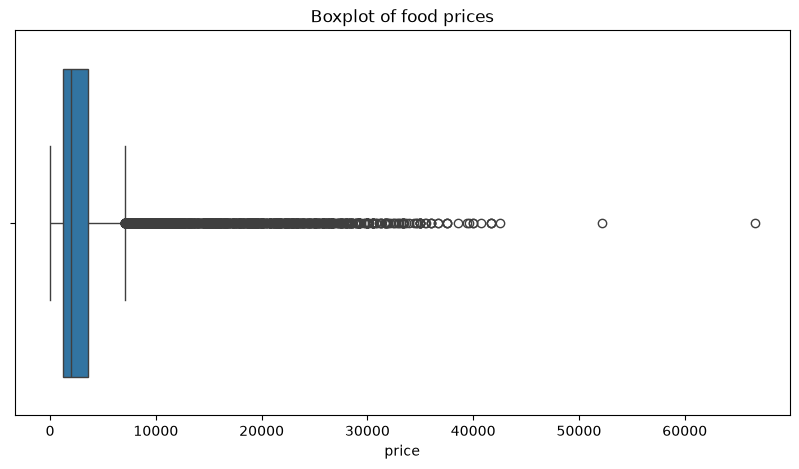

In [14]:
## visualizing
plt.figure(figsize=(10,5))
sns.boxplot(x=df['price'])
plt.title("Boxplot of food prices")
plt.show()

In [ ]:
##Data intergration
##its only one csv no need of data intergration

In [17]:
## Data transformation
## Encoding categoric data using one-hot Encoding

encoded_data = pd.get_dummies(
    df,columns = ['pricetype'],
    drop_first=True
)
encoded_data.head()

,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,currency,price,usdprice,pricetype_Wholesale
0,2006-01-15,Busia,Samia-bugwe,Busia,2665,0.47,34.09,cereals and tubers,Maize,51,KG,actual,UGX,298.40,0.17,True
1,2006-01-15,Kampala,Central Kampala,Owino,258,0.32,32.57,cereals and tubers,Maize,51,KG,actual,UGX,345.42,0.20,True
2,2006-01-15,Kampala,Central Kampala,Owino,258,0.32,32.57,cereals and tubers,Rice,52,KG,actual,UGX,1013.40,0.58,True
3,2006-01-15,Lira,Lira Municipality,Lira,263,2.23,32.91,cereals and tubers,Maize,51,KG,actual,UGX,247.76,0.14,True
4,2006-02-15,Busia,Samia-bugwe,Busia,2665,0.47,34.09,cereals and tubers,Maize,51,KG,actual,UGX,296.59,0.17,True


In [21]:
##convert dates
df['dates'] = pd.to_datetime(df['date'])
df['year'] = df['dates'].dt.year
df['month'] = df['dates'].dt.month
df[['dates','year','month']].head()

,dates,year,month
0,2006-01-15,2006,1
1,2006-01-15,2006,1
2,2006-01-15,2006,1
3,2006-01-15,2006,1
4,2006-02-15,2006,2


In [33]:
##feature scaling
Scaler = StandardScaler()
Scaled_prices = Scaler.fit_transform(
    df[['price','usdprice']]
)
print(Scaled_prices[:5])

[[-0.77135914 -0.70507852]
 [-0.75881105 -0.67551964]
 [-0.58054915 -0.30110713]
 [-0.78487329 -0.7346374 ]
 [-0.77184217 -0.70507852]]


In [ ]:
##Data reduction and splitting
##it involves removing unnecessary information while retaining useful information


In [35]:
##Train and test splitting
x = df[
    [
        'year' , 'month', 'market' , 'commodity','category'
    ]
]
y = df['price']

In [36]:
##Exploratory Data Analysis
##Descriptive statistics

df['price'].describe()

count    34328.000000
mean      3188.824076
std       3747.237874
min          2.000000
25%       1200.000000
50%       2000.000000
75%       3563.000000
max      66608.000000
Name: price, dtype: float64

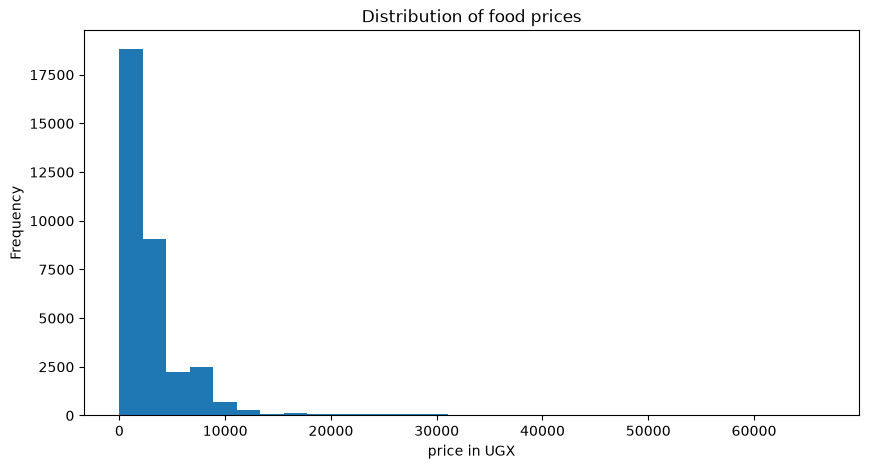

In [39]:
##Univariate Analysis
plt.figure(figsize =(10,5) )
plt.hist(df['price'] , bins=30)
plt.title("Distribution of food prices")
plt.xlabel("price in UGX")
plt.ylabel("Frequency")
plt.show()

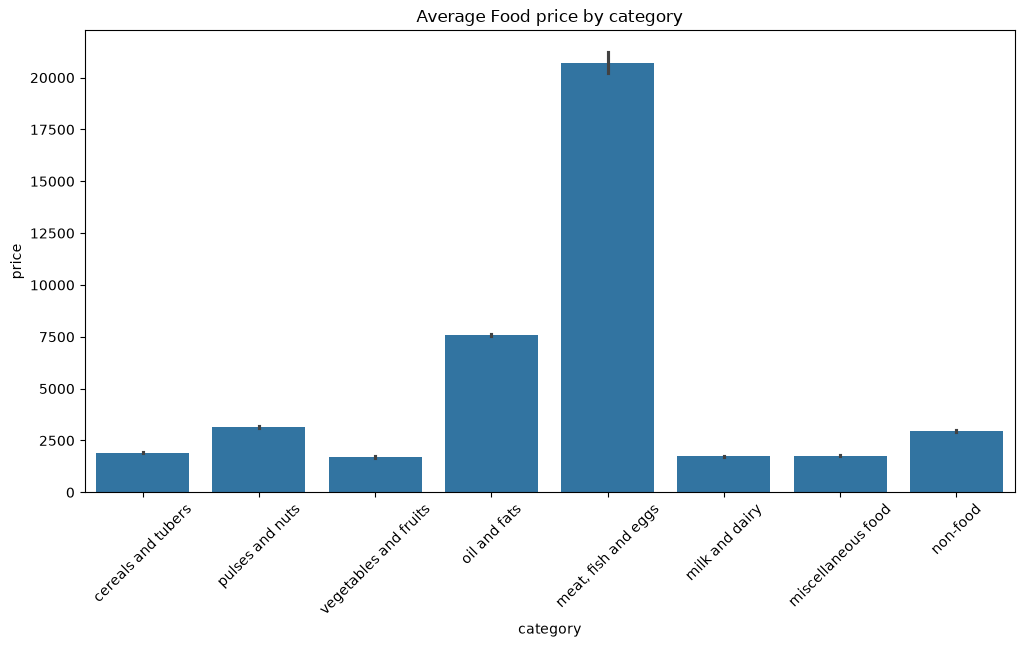

In [41]:
##Bivariate and multivariate Analysis
plt.figure(figsize=(12,6))
sns.barplot(
    data=df,
    x='category' ,
    y = 'price'

)
plt.xticks(rotation = 45)
plt.title("Average Food price by category")
plt.show()

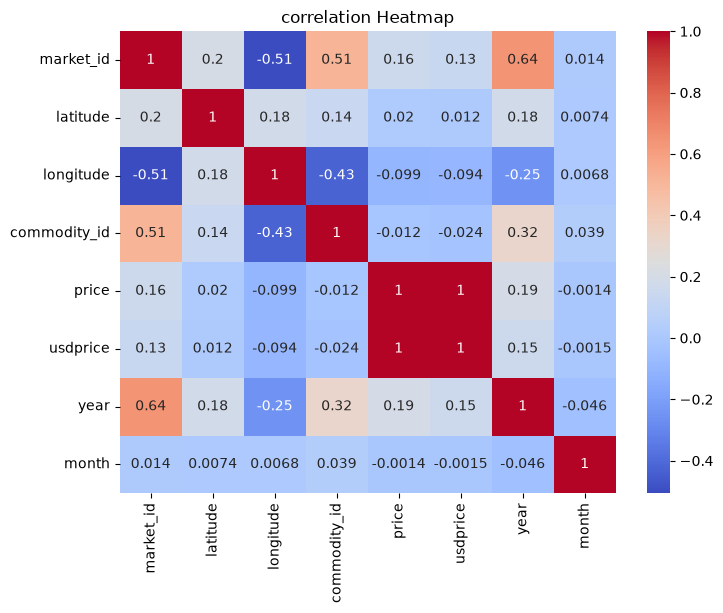

In [46]:
## correlation heatmap graph
plt.figure(figsize=(8,6))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
     
)
plt.title("correlation Heatmap")
plt.show()

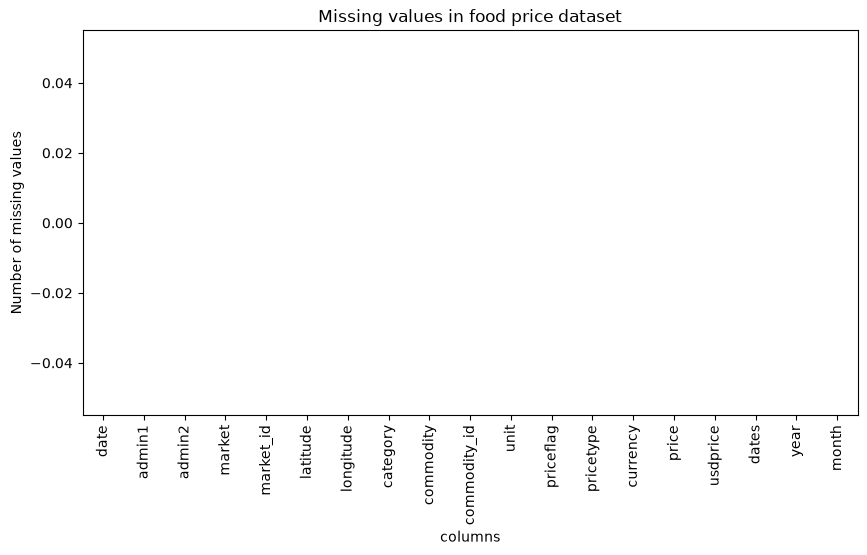

In [43]:
##missing data visualization
plt.figure(figsize=(10,5))
df.isnull().sum().plot(kind='bar')
plt.title("Missing values in food price dataset")
plt.xlabel("columns")
plt.ylabel("Number of missing values")
plt.show()


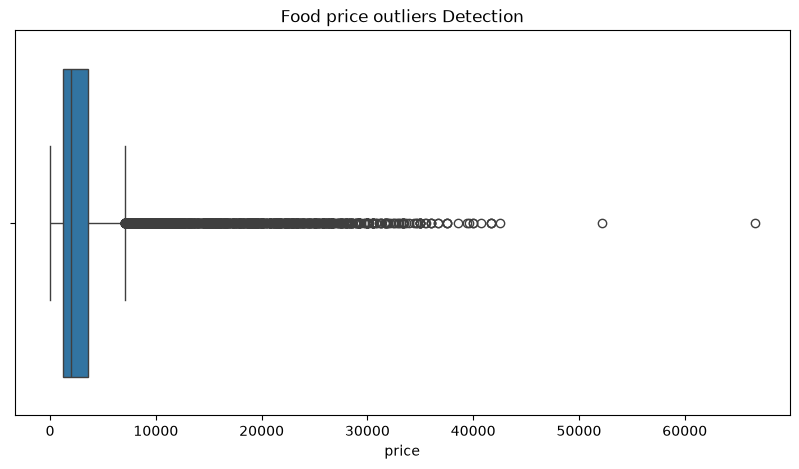

In [47]:
##outlier visualisation
plt.figure(figsize=(10,5))
sns.boxplot(x=df['price'])
plt.title("Food price outliers Detection")
plt.show()

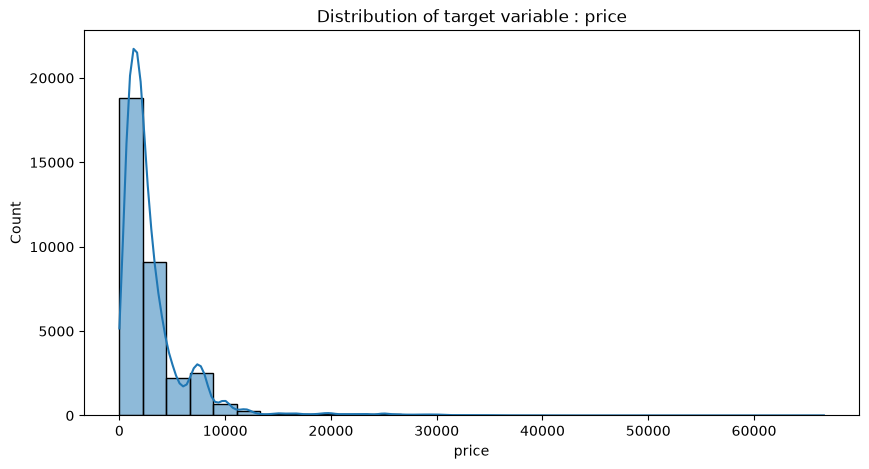

In [49]:
##Target variable analysis
plt.figure(figsize=(10,5))
sns.histplot(
    df['price'],
    bins=30,
    kde=True
)
plt.title("Distribution of target variable : price")
plt.show()